# Hessian estimation from regression-tree splits vs. PHD: 2D OPFData study (Maple)

**Objective.** Estimate how the optimal operating cost of an electricity grid curves jointly with 2 selected
demand inputs. Reconstruct a Hessian from the splits of an ordinary CART tree with **Algorithm 1 of the
manuscript, implemented line by line**, and compare it with a residual-based Principal Hessian Directions (PHD)
estimate. Then determine, with a controlled experiment on the same tree, where any inconsistency comes from.

**Data.** IEEE-118 OPFData subset, 5,000 records, headerless CSV. Column 0 is the optimal cost (response); columns
1, 2 are per-unit active demands at 2 load buses (predictors), labelled Load 1..2. Columns 1–99 of the file are
consistent with the 99 load elements of the IEEE-118 case (their means sum to 42.40 p.u. $= 4{,}240$ MW; the case
nominal is 4,242 MW). Physical bus identities per column are not established. Only the first 3 columns are read;
the 2 GB file is not used.

**Scope.** Neither matrix is a true Hessian; the data carry no reference derivative. The checks are: whether every
row of the tree system is identified, whether the raw tree matrix is symmetric, how the two estimates differ, and
what the controlled experiment attributes the inconsistency to. Eigenanalysis and physical interpretation are
outside this study.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import hessian_tools as L
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1e3 else f"{v:,.2f}")
display(L.software_versions())

,version
python,3.13.18
numpy,2.5.3
pandas,3.0.5
scikit-learn,1.9.1
matplotlib,3.11.2
platform,Linux-6.18.44-fc-v310-x86_64-with-glibc2.39


## 1. Data and experimental configuration

All 5,000 observations are retained in their original units; nothing is standardised. Two tree settings are reported
throughout: **A** `max_depth=7, min_samples_leaf=1` (scikit-learn's default leaf size, matching the Cedar baseline)
and **B** `max_depth=7, min_samples_leaf=50`.

In [2]:
D = 2
X, y, csv_path = L.load_opf(D)
print("file:", csv_path)
print("X shape:", X.shape, "| y shape:", y.shape)
display(L.describe_inputs(X, y))
print("predictor correlation matrix:")
display(L.matrix_frame(np.corrcoef(X.T), "corr"))

file: /mnt/user-data/uploads/118_ieee_smol.csv
X shape: (5000, 2) | y shape: (5000,)


,count,mean,std,min,max
cost (col 0),5000,"93,757.84","13,560.62","69,269.90","124,285.53"
Load 1 (col 1),5000,0.5104,0.0833,0.3294,0.7332
Load 2 (col 2),5000,0.2001,0.0323,0.1297,0.2868


predictor correlation matrix:


,Load 1,Load 2
corr,,
Load 1,1.0000,0.4731
Load 2,0.4731,1.0000


## 2. The method in plain terms

We have 2 inputs and one output, the cost. We want three numbers: the curvatures $Q_{11}$, $Q_{22}$ and the interaction $Q_{12}$.

**Step 1 — one slope per split.** Take an internal node that splits on Load $s$: a box $\prod_k[\ell_k,u_k]$ with a cut
at $\tau$, left-child node mean $\mu_L$ and right-child node mean $\mu_R$ (the average observed cost of the rows in
each child — nothing is sampled). Then

$$
\gamma \;=\; \frac{\mu_R-\mu_L}{(u_s-\ell_s)/2}
$$

is a slope of cost with respect to Load $s$: the two child boxes' centres are half the box width apart along that
axis, so this is rise over run.

**Step 2 — where that slope is measured.** The slope is not "at the cut". For a quadratic cost it equals the
derivative at one point $z$ in the box: along the split axis $z_s=(\ell_s+\tau+u_s)/3$, the average of the three
breakpoints; along every other axis $z_k=(\ell_k+u_k)/2$, the box middle. Each split now reads: *the Load-$s$ slope at
location $z$ is $\gamma$.*

**Step 3 — two slopes make one equation.** Take two Load-1 splits $A$ and $B$. If the cost is quadratic, the Load-1
slope changes linearly as one moves, so

$$
\gamma_B-\gamma_A = Q_{11}\,(z_{B,1}-z_{A,1}) + Q_{12}\,(z_{B,2}-z_{A,2}) .
$$

The slope changed because we moved along Load 1 (curvature $Q_{11}$ acts) and along the other axes (interactions act).
Two special cases: if $A$ and $B$ sit at the same height in the other axes, only $Q_{11}$ remains; if they sit at the
same Load-1 position but different heights, only the interaction terms remain — *the Load-1 slope changed as I moved
in Load 2*, which is what an interaction means.

**Step 4 — many equations, solve.** Every ordered pair of distinct Load-1 splits with $z_A\neq z_B$ gives one equation
in $(Q_{11}, Q_{12})$. Stack them into $V_1 q_1 \approx y_1$ and solve by least squares: row 1 of $\tilde Q$. Repeat for each
axis. The pairs must spread in every direction or the equations cannot separate the unknowns — that is the rank
check, $\operatorname{rank}(V_s)=2$, else "not identified".

**Step 5 — the symmetry check.** Row 1 gives $\tilde Q_{12}$ from Load-1 splits; row 2 gives $\tilde Q_{21}$ from
Load-2 splits. A true Hessian has $Q_{12}=Q_{21}$, and the two were computed from completely different splits, so
their gap measures the method's error without any truth. Algorithm 1's last line returns
$\hat Q=\tfrac12(\tilde Q+\tilde Q^\top)$; this notebook inspects $\tilde Q$ *before* that line. In 2D there are
one distinct off-diagonal pair: (1,2).

**Where this can fail.** Step 2 assumes rows fill each box evenly — that is where the $1/3$ and the box middle come
from. If they do not, $z$ is mislocated and the Step-3 equations are built on the wrong coordinates. And each $\mu$ is
a node mean over the rows in a child, so it is noisy; the method differences these means twice.

## 3. CART fit and first-derivative extraction

The tree is fitted to the raw data. The table lists every internal node: split axis, extent along it, threshold
$\tau$, the two child node means, the Step-1 slope $\gamma$ and the Step-2 location $z$ (columns `c_k`). The root box
is the observed data range per axis.

In [3]:
settings = {"A": dict(max_depth=7, min_samples_leaf=1), "B": dict(max_depth=7, min_samples_leaf=50)}
trees, nodes, splits = {}, {}, {}
for k, kw in settings.items():
    trees[k] = L.fit_cart(X, y, **kw)
    nodes[k] = L.nodes_from_cart(trees[k], X)
    splits[k] = L.split_table(nodes[k])
    print(f"setting {k}: {kw} -> {len(splits[k])} internal nodes, {int(trees[k].get_n_leaves())} leaves; "
          + ", ".join(f"{s}: {(splits[k]['split axis']==s).sum()}" for s in sorted(splits[k]['split axis'].unique())))
print("\nsetting B, first rows of the split table:")
display(splits["B"].head(12))

setting A: {'max_depth': 7, 'min_samples_leaf': 1} -> 126 internal nodes, 127 leaves; Load 1: 67, Load 2: 59
setting B: {'max_depth': 7, 'min_samples_leaf': 50} -> 59 internal nodes, 60 leaves; Load 1: 31, Load 2: 28

setting B, first rows of the split table:


,node,depth,split axis,lo_s,tau,hi_s,n,n_left,n_right,mean_left,mean_right,gamma (eq. 3),c_1,c_2
0,1,1,Load 1,0.3294,0.5362,0.7332,2318,1844,474,"82,326.31","97,262.42","73,973.91",0.5330,0.1622
1,60,1,Load 1,0.3294,0.4738,0.7332,2682,574,2108,"90,816.76","103,770.54","64,155.99",0.5122,0.2408
2,2,2,Load 1,0.3294,0.4457,0.5362,1844,869,975,"79,013.41","85,279.03","60,585.99",0.4371,0.1622
3,45,2,Load 1,0.5362,0.5956,0.7332,474,327,147,"93,934.11","104,666.23","108,962.67",0.6217,0.1622
4,3,3,Load 1,0.3294,0.3797,0.4457,869,222,647,"74,882.84","80,430.70","95,420.90",0.3849,0.1622
5,57,3,Load 1,0.5956,0.6309,0.7332,147,81,66,"101,200.94","108,919.09","112,120.89",0.6532,0.1622
6,62,3,Load 1,0.3294,0.4311,0.4738,327,152,175,"82,760.84","89,675.33","95,755.62",0.4115,0.2046
7,71,3,Load 1,0.3294,0.4492,0.4738,247,109,138,"92,165.44","100,072.16","109,496.43",0.4175,0.2507
8,79,3,Load 1,0.4738,0.6029,0.7332,1365,1018,347,"98,346.03","108,702.03","79,845.30",0.6033,0.2146
9,4,4,Load 1,0.3294,0.3512,0.3797,222,55,167,"72,890.42","75,539.03","105,433.42",0.3534,0.1622


## 4. Algorithm 1: $\tilde Q$ before symmetrisation

`hessian_tools.algorithm1_hessian` follows the pseudocode line by line (lines 1–4 slopes and locations; 5–11 ordered
pairs with $s_A=s_B$, $z_A\neq z_B$; 12–18 rank check and least squares per row; 19 symmetrisation). Diagnostics per
row $s$: nodes splitting axis $s$, rows in $V_s$ (ordered pairs, so twice the number of unordered pairs), rank of
$V_s$, condition number.

Two cross-checks: the Week 45 solver (unordered pairs, same equations) and the Cedar centred-regression formulation
must both reproduce $\tilde Q$ to rounding.

In [4]:
Q_tilde, Q_hat, diag = {}, {}, {}
for k in settings:
    res = L.algorithm1_hessian(nodes[k], D)
    Q_tilde[k], Q_hat[k], diag[k] = res["Q_tilde"], res["Q_hat"], res["diag"]
    w45, _ = L.cart_hessian_raw(nodes[k], D)
    alt = L.centred_regression_rows(nodes[k], D)
    print(f"--- setting {k}: identified = {res['identified']} ---")
    display(diag[k])
    print("Q_tilde (before line 19, NOT symmetrised):")
    display(L.matrix_frame(Q_tilde[k], f"Q_tilde {k}"))
    print(f"max |Algorithm 1 - Week 45 solver| = {np.nanmax(np.abs(Q_tilde[k]-w45)):.2e} | "
          f"max |Algorithm 1 - centred regression| = {np.nanmax(np.abs(Q_tilde[k]-alt)):.2e}\n")

--- setting A: identified = True ---


,row,n_nodes,n_rows_V,rank,cond
0,Load 1,67,4422,2,3.2260
1,Load 2,59,3422,2,2.3866


Q_tilde (before line 19, NOT symmetrised):


,Load 1,Load 2
Q_tilde A,,
Load 1,"210,716.98","-733,998.62"
Load 2,"-3,154,084.83","-3,905,774.69"


max |Algorithm 1 - Week 45 solver| = 1.40e-09 | max |Algorithm 1 - centred regression| = 3.26e-09

--- setting B: identified = True ---


,row,n_nodes,n_rows_V,rank,cond
0,Load 1,31,930,2,3.2407
1,Load 2,28,756,2,2.3051


Q_tilde (before line 19, NOT symmetrised):


,Load 1,Load 2
Q_tilde B,,
Load 1,"109,142.88","-192,840.71"
Load 2,"-124,378.14","-531,240.05"


max |Algorithm 1 - Week 45 solver| = 2.76e-10 | max |Algorithm 1 - centred regression| = 3.06e-10



## 5. PHD: curvature from residuals

Residual-based Principal Hessian Directions (Li, 1992). Centre the inputs, $X_c = X-\bar x$; covariance
$\Sigma = X_c^\top X_c/n$ (divisor $n$); fit an ordinary least-squares line $y \approx \beta_0+\beta^\top x$ and keep the
residuals $r$; form $M=\frac1n\sum_i r_i\,x_{c,i}x_{c,i}^\top$; estimate

$$
\hat H_{\mathrm{PHD}} \;=\; \Sigma^{-1} M\, \Sigma^{-1},
$$

in original units (cost per squared demand unit). Under a Gaussian input distribution $M$ identifies the average
Hessian of $E[y\mid x]$; the loads here are products of uniform factors and correlated, so PHD is a baseline with an
assumption, not a reference. $M$ is symmetric by construction, so the reported asymmetry of $\hat H_{\mathrm{PHD}}$
is at rounding level.

In [5]:
H_phd, cond_sigma, asym_phd = L.phd_residual(X, y)
print(f"condition number of Sigma: {cond_sigma:.2f} | Frobenius asymmetry of H_PHD: {asym_phd:.1e}")
display(L.matrix_frame(H_phd, "PHD"))

condition number of Sigma: 9.20 | Frobenius asymmetry of H_PHD: 1.5e-16


,Load 1,Load 2
PHD,,
Load 1,"140,086.44","-474,727.79"
Load 2,"-474,727.79","830,031.37"


## 6. Estimates side by side (original units)

In [6]:
for k in settings:
    print(f"Algorithm 1, setting {k} — Q_tilde (before line 19):"); display(L.matrix_frame(Q_tilde[k], f"Q_tilde {k}"))
    print(f"Algorithm 1, setting {k} — Q_hat (line 19 output):"); display(L.matrix_frame(Q_hat[k], f"Q_hat {k}"))
print("PHD:"); display(L.matrix_frame(H_phd, "PHD"))

Algorithm 1, setting A — Q_tilde (before line 19):


,Load 1,Load 2
Q_tilde A,,
Load 1,"210,716.98","-733,998.62"
Load 2,"-3,154,084.83","-3,905,774.69"


Algorithm 1, setting A — Q_hat (line 19 output):


,Load 1,Load 2
Q_hat A,,
Load 1,"210,716.98","-1,944,041.73"
Load 2,"-1,944,041.73","-3,905,774.69"


Algorithm 1, setting B — Q_tilde (before line 19):


,Load 1,Load 2
Q_tilde B,,
Load 1,"109,142.88","-192,840.71"
Load 2,"-124,378.14","-531,240.05"


Algorithm 1, setting B — Q_hat (line 19 output):


,Load 1,Load 2
Q_hat B,,
Load 1,"109,142.88","-158,609.43"
Load 2,"-158,609.43","-531,240.05"


PHD:


,Load 1,Load 2
PHD,,
Load 1,"140,086.44","-474,727.79"
Load 2,"-474,727.79","830,031.37"


## 7. Numerical symmetry check of $\tilde Q$

For each distinct pair $i<j$: $\tilde Q_{ij}$ (from the row solved with Load-$i$ splits), $\tilde Q_{ji}$ (from Load-$j$
splits), the signed gap, the absolute gap, and the gap relative to the larger of the two entries. The mean, median and
maximum are summaries across the one distinct off-diagonal pair — (1,2) — not across observations. Nothing is symmetrised here.

In [7]:
for k in settings:
    pairs, summary = L.symmetry_pairs(Q_tilde[k])
    print(f"--- setting {k} ---"); display(pairs); display(summary)

--- setting A ---


,"pair (i,j)","H[i,j]","H[j,i]","signed gap H[i,j]-H[j,i]",abs gap,"abs gap / max(|H[i,j]|,|H[j,i]|)"
0,"(1,2)","-733,998.62","-3,154,084.83","2,420,086.20","2,420,086.20",0.7673


,distinct pairs,mean abs gap,median abs gap,max abs gap
0,1,"2,420,086.20","2,420,086.20","2,420,086.20"


--- setting B ---


,"pair (i,j)","H[i,j]","H[j,i]","signed gap H[i,j]-H[j,i]",abs gap,"abs gap / max(|H[i,j]|,|H[j,i]|)"
0,"(1,2)","-192,840.71","-124,378.14","-68,462.57","68,462.57",0.3550


,distinct pairs,mean abs gap,median abs gap,max abs gap
0,1,"68,462.57","68,462.57","68,462.57"


## 8. Disagreement with PHD

First $\tilde Q$ against PHD entry by entry; then $\hat Q=\tfrac12(\tilde Q+\tilde Q^\top)$ against PHD, reported only
after the symmetry table so that line 19 is a visible step. Differences are between two estimates; no column is a
truth value.

In [8]:
for k in settings:
    print(f"--- setting {k}: Q_tilde vs PHD ---")
    display(L.comparison_table(Q_tilde[k], H_phd, f"Q_tilde {k}"))
    asym = np.linalg.norm(Q_tilde[k] - Q_tilde[k].T) / np.linalg.norm(Q_tilde[k])
    print(f"--- setting {k}: Q_hat vs PHD   (asymmetry of Q_tilde ||Q-Q^T||/||Q|| = {asym:.3f}) ---")
    display(L.comparison_table(Q_hat[k], H_phd, f"Q_hat {k}"))

--- setting A: Q_tilde vs PHD ---


,entry,Q_tilde A,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","210,716.98","140,086.44","70,630.54","70,630.54"
1,"(1,2)","-733,998.62","-474,727.79","-259,270.83","259,270.83"
2,"(2,1)","-3,154,084.83","-474,727.79","-2,679,357.04","2,679,357.04"
3,"(2,2)","-3,905,774.69","830,031.37","-4,735,806.06","4,735,806.06"


--- setting A: Q_hat vs PHD   (asymmetry of Q_tilde ||Q-Q^T||/||Q|| = 0.674) ---


,entry,Q_hat A,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","210,716.98","140,086.44","70,630.54","70,630.54"
1,"(1,2)","-1,944,041.73","-474,727.79","-1,469,313.94","1,469,313.94"
2,"(2,1)","-1,944,041.73","-474,727.79","-1,469,313.94","1,469,313.94"
3,"(2,2)","-3,905,774.69","830,031.37","-4,735,806.06","4,735,806.06"


--- setting B: Q_tilde vs PHD ---


,entry,Q_tilde B,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","109,142.88","140,086.44","-30,943.55","30,943.55"
1,"(1,2)","-192,840.71","-474,727.79","281,887.08","281,887.08"
2,"(2,1)","-124,378.14","-474,727.79","350,349.65","350,349.65"
3,"(2,2)","-531,240.05","830,031.37","-1,361,271.42","1,361,271.42"


--- setting B: Q_hat vs PHD   (asymmetry of Q_tilde ||Q-Q^T||/||Q|| = 0.164) ---


,entry,Q_hat B,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","109,142.88","140,086.44","-30,943.55","30,943.55"
1,"(1,2)","-158,609.43","-474,727.79","316,118.36","316,118.36"
2,"(2,1)","-158,609.43","-474,727.79","316,118.36","316,118.36"
3,"(2,2)","-531,240.05","830,031.37","-1,361,271.42","1,361,271.42"


## 9. Figures

Each matrix is shown directly. Colour indicates sign and magnitude; annotations are in **millions of cost units per
squared demand unit**. The $\tilde Q$ figures are intentionally not symmetrised.

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


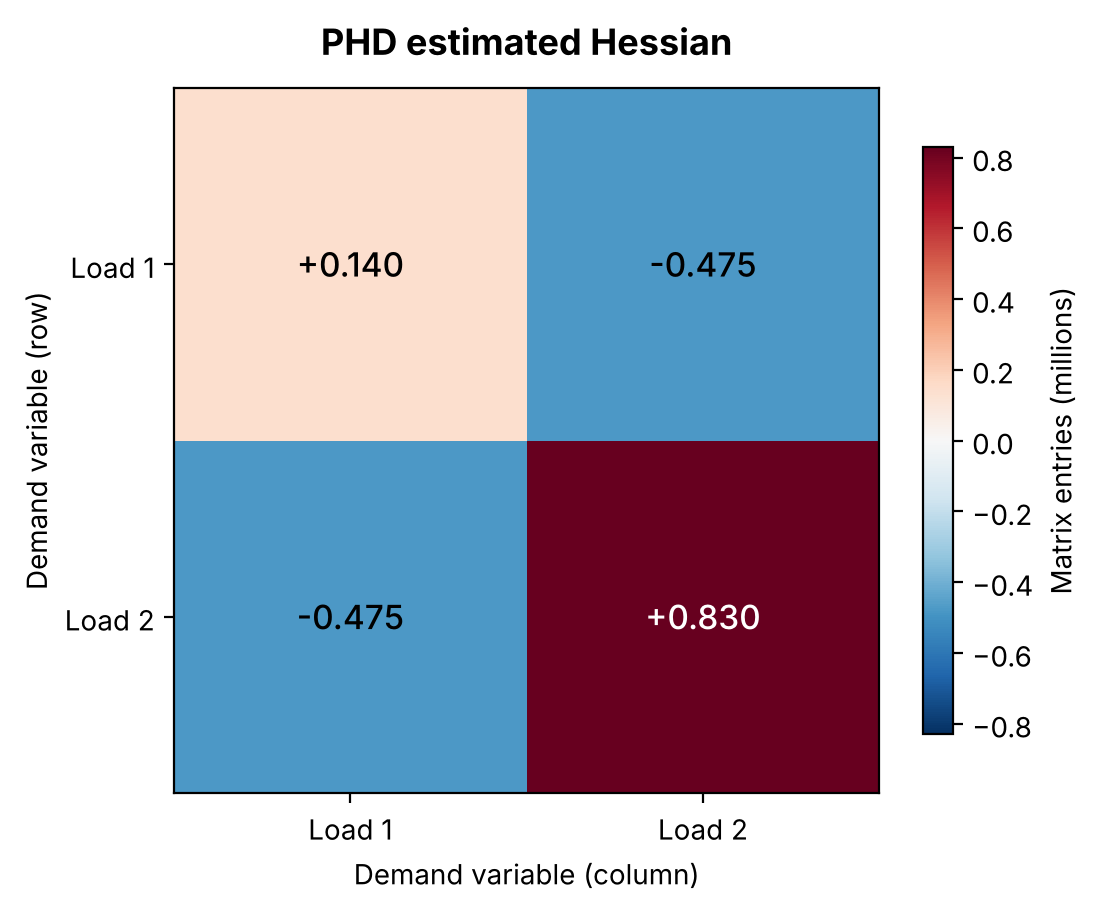

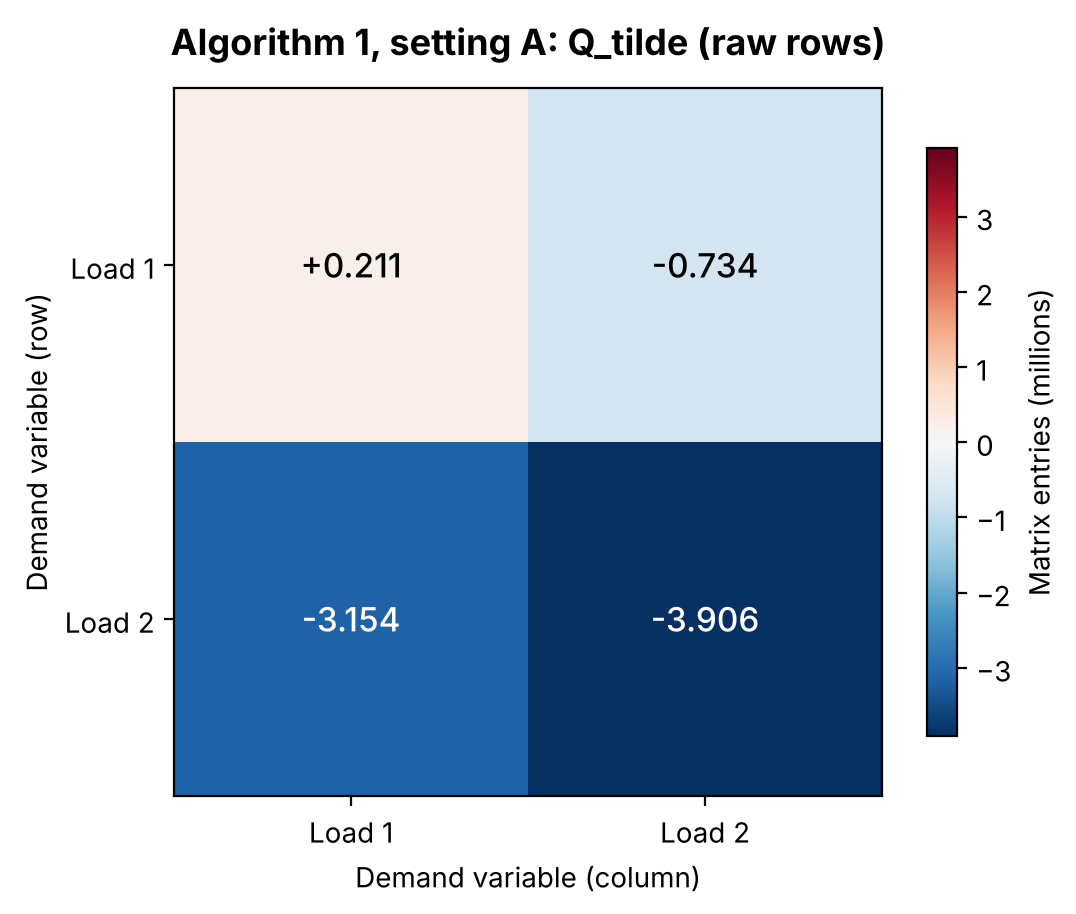

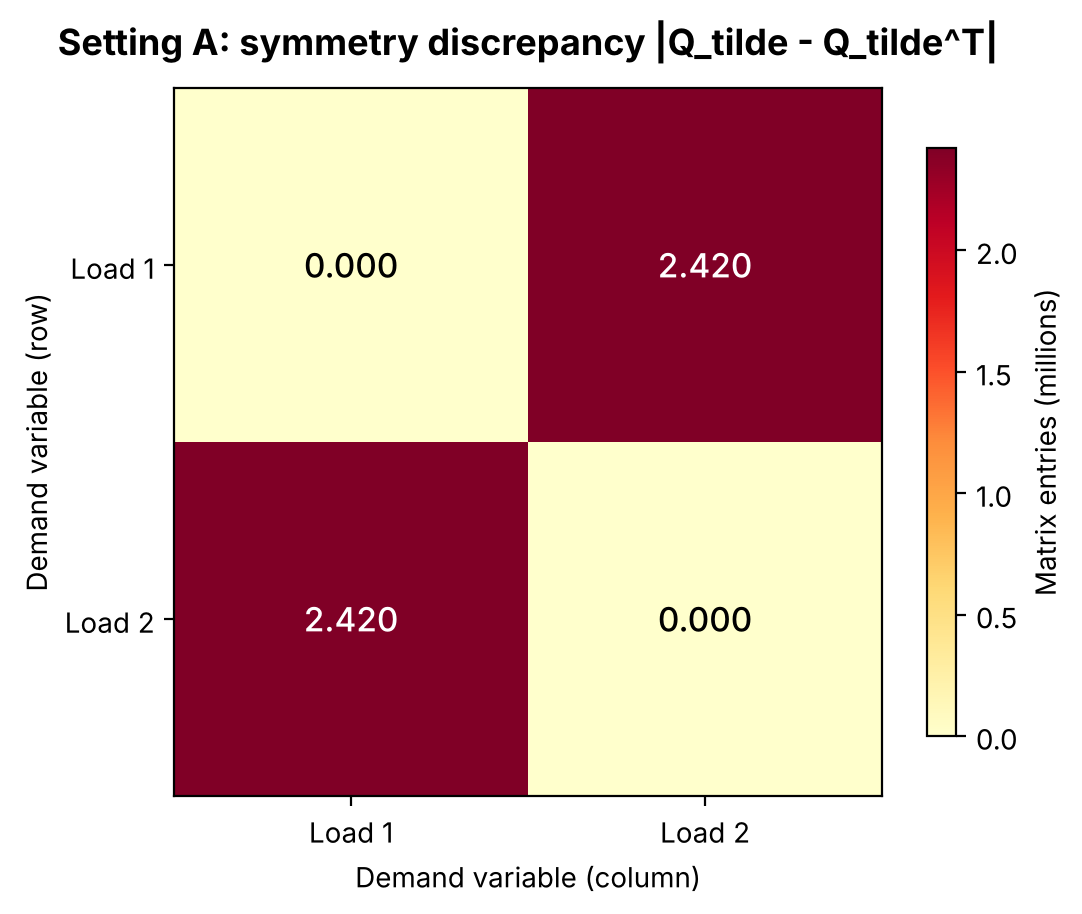

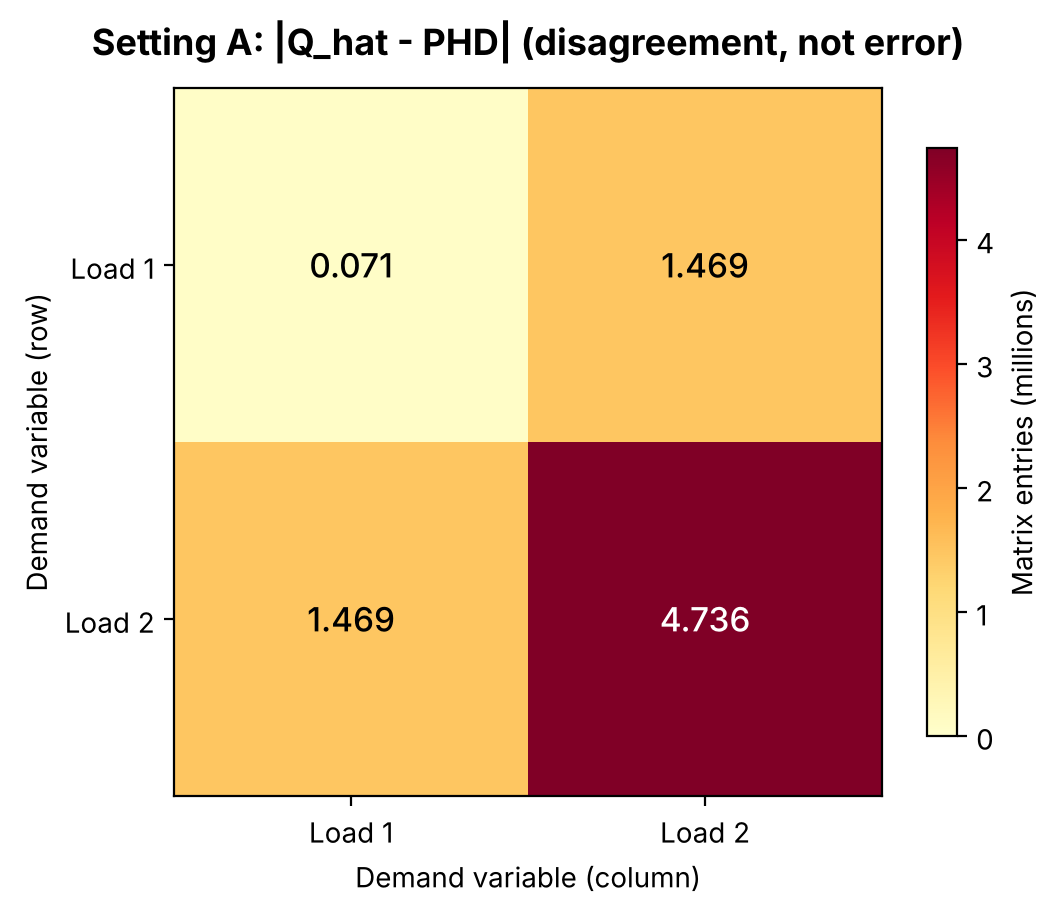

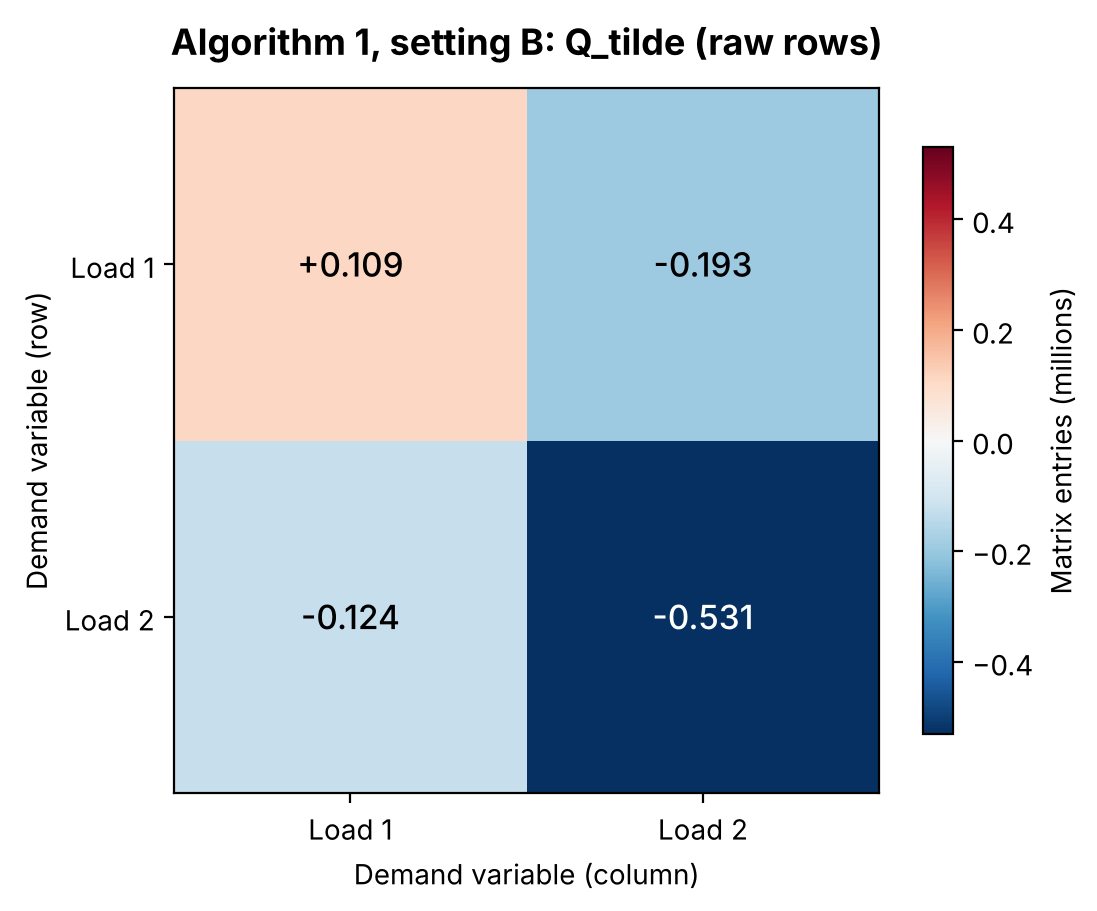

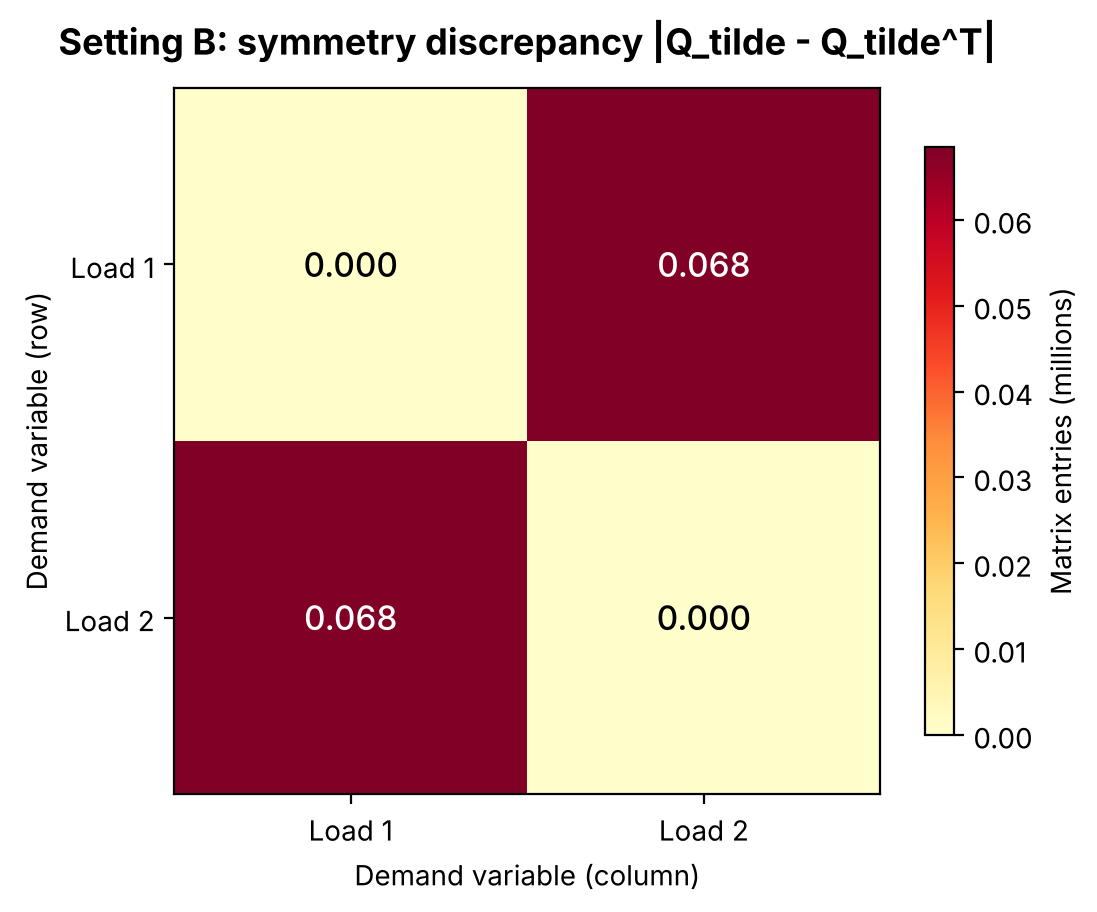

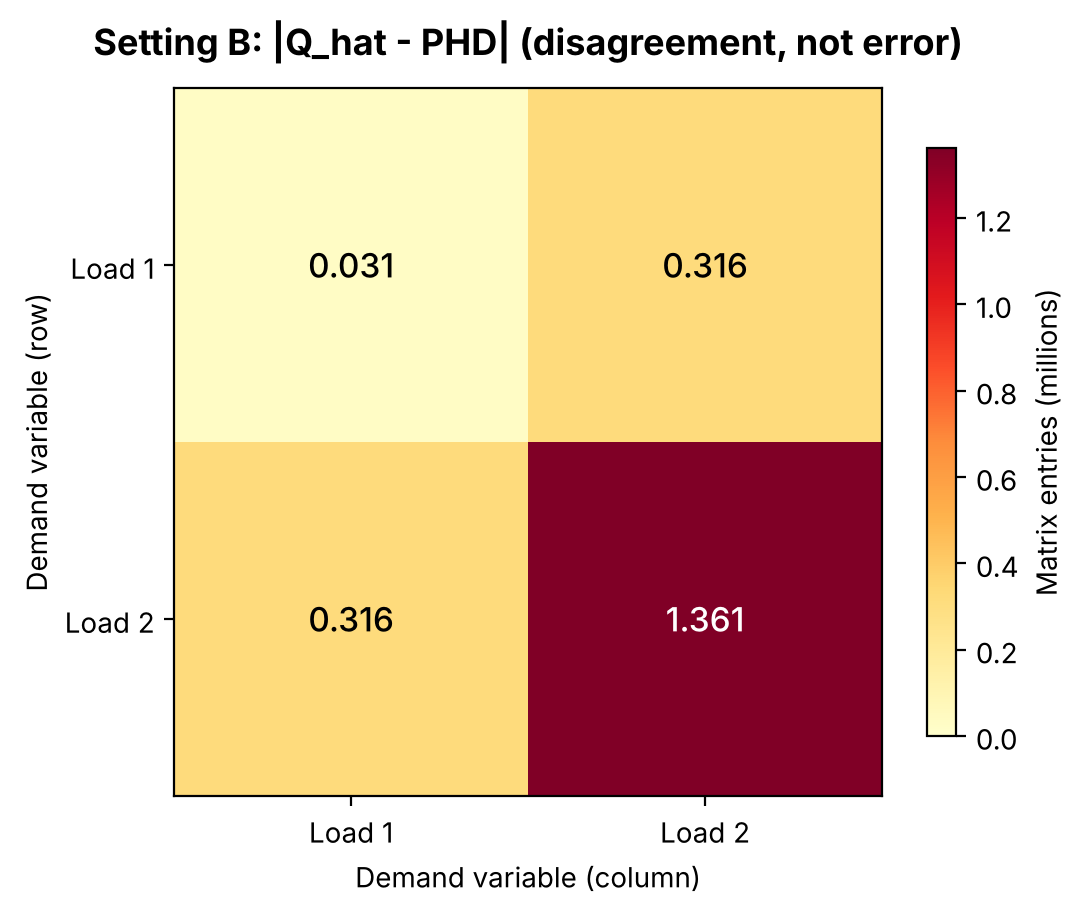

In [9]:
def plot_hessian(matrix, title, absolute=False):
    """Display one annotated matrix in millions of original units.

    Args:
        matrix: square matrix to plot.
        title: figure title naming the estimator or diagnostic.
        absolute: use a non-negative colour scale (for gaps and |differences|).
    """
    values = np.asarray(matrix, float) / 1e6
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    if absolute:
        image = ax.imshow(values, cmap="YlOrRd", vmin=0)
    else:
        vmax = max(0.1, float(np.nanmax(np.abs(values))))
        image = ax.imshow(values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            color = "white" if abs(values[i, j]) > 0.60 * max(np.nanmax(np.abs(values)), 1e-12) else "black"
            ax.text(j, i, f"{values[i, j]:+.3f}" if not absolute else f"{values[i, j]:.3f}",
                    ha="center", va="center", fontsize=12, weight="medium", color=color)
    ticks = np.arange(values.shape[0])
    ax.set_xticks(ticks, [f"Load {j+1}" for j in ticks]); ax.set_yticks(ticks, [f"Load {j+1}" for j in ticks])
    ax.set_xlabel("Demand variable (column)"); ax.set_ylabel("Demand variable (row)")
    ax.set_title(title, fontsize=13, weight="bold", pad=12)
    fig.colorbar(image, ax=ax, shrink=.83, label="Matrix entries (millions)")
    fig.tight_layout(); plt.show()


plot_hessian(H_phd, "PHD estimated Hessian")
for k in settings:
    plot_hessian(Q_tilde[k], f"Algorithm 1, setting {k}: Q_tilde (raw rows)")
    plot_hessian(np.abs(Q_tilde[k] - Q_tilde[k].T), f"Setting {k}: symmetry discrepancy |Q_tilde - Q_tilde^T|", absolute=True)
    plot_hessian(np.abs(Q_hat[k] - H_phd), f"Setting {k}: |Q_hat - PHD| (disagreement, not error)", absolute=True)

## 10. Controlled check on the same partitions: where does the inconsistency come from?

Algorithm 1 is exact for a quadratic when each node's value is the exact mean of that quadratic over the node's box
under the uniform measure. On the fitted partitions above, a quadratic with a known random symmetric Hessian $Q$ is
evaluated three ways and reconstructed with the same code:

- **(a) exact box means** — the integral of the quadratic over each box: tests the geometry and the code only;
- **(b) node means at the real rows** — the quadratic evaluated at the OPFData rows in each box and averaged, no
  observation noise: adds the effect of how many rows each box holds *and* where they sit;
- **(c) uniform resample** — the same number of points per box as in (b), placed uniformly at random on the box
  (the one place in this notebook where anything is sampled): adds only the "how many rows" effect.

Errors are $\max|\tilde Q-Q|/\max|Q|$. The final table reports, per internal node, how far the real rows' centroid
sits from the box centre relative to the box width (0 under the uniform assumption).

In [10]:
rows = []
for k in settings:
    for seed in (0, 1, 2):
        c = L.known_quadratic_check(nodes[k], X, D, seed)
        scale = np.max(np.abs(c["Q_true"]))
        rows.append({"setting": k, "seed": seed,
                     "(a) exact box means": np.nanmax(np.abs(c["exact_box_means"] - c["Q_true"])) / scale,
                     "(b) node means, real rows": np.nanmax(np.abs(c["sample_means"] - c["Q_true"])) / scale,
                     "(c) uniform resample": np.nanmax(np.abs(c["uniform_resample"] - c["Q_true"])) / scale,
                     "ranks (a/b/c)": f"{c['rank_exact']}/{c['rank_sample']}/{c['rank_uniform']}"})
ctrl = pd.DataFrame(rows)
with pd.option_context("display.float_format", lambda v: f"{v:.2e}" if v < 1e-6 else f"{v:.2f}"):
    display(ctrl)
c = L.known_quadratic_check(nodes["B"], X, D, 0)
print("setting B, seed 0 — known Q:"); display(L.matrix_frame(c["Q_true"], "Q true"))
print("(a) exact box means:"); display(L.matrix_frame(c["exact_box_means"], "(a)"))
print("(b) node means at the real rows:"); display(L.matrix_frame(c["sample_means"], "(b)"))
print("(c) uniform resample:"); display(L.matrix_frame(c["uniform_resample"], "(c)"))

,setting,seed,(a) exact box means,"(b) node means, real rows",(c) uniform resample,ranks (a/b/c)
0,A,0,1.80e-13,33.26,60.13,"[2, 2]/[2, 2]/[2, 2]"
1,A,1,1.46e-14,20.05,20.91,"[2, 2]/[2, 2]/[2, 2]"
2,A,2,2.69e-14,15.09,4.77,"[2, 2]/[2, 2]/[2, 2]"
3,B,0,6.61e-14,6.90,3.09,"[2, 2]/[2, 2]/[2, 2]"
4,B,1,3.66e-15,3.09,2.02,"[2, 2]/[2, 2]/[2, 2]"
5,B,2,2.80e-14,2.28,1.68,"[2, 2]/[2, 2]/[2, 2]"


setting B, seed 0 — known Q:


,Load 1,Load 2
Q true,,
Load 1,0.1257,0.2542
Load 2,0.2542,0.1049


(a) exact box means:


,Load 1,Load 2
(a),,
Load 1,0.1257,0.2542
Load 2,0.2542,0.1049


(b) node means at the real rows:


,Load 1,Load 2
(b),,
Load 1,0.1573,0.5534
Load 2,0.3150,-1.6486


(c) uniform resample:


,Load 1,Load 2
(c),,
Load 1,0.1849,0.2858
Load 2,0.2936,-0.6811


In [11]:
u = L.within_cell_uniformity(nodes["B"], X)
print("setting B: |row centroid − box centroid| / box width per axis; last row = mean over internal nodes")
display(u.tail(6))

setting B: |row centroid − box centroid| / box width per axis; last row = mean over internal nodes


,node,depth,n,|offset|/width axis 1,|offset|/width axis 2
54,16,6,265,0.0611,0.0083
55,12,5,135,0.0134,0.1298
56,4,4,222,0.1086,0.0704
57,6,5,167,0.0146,0.0737
58,8,6,100,0.0354,0.0651
59,mean,,,0.0748,0.0886


## 11. Findings and limitations

1. **The implementation is Algorithm 1.** The Week 45 solver and the Cedar centred regression reproduce $\tilde Q$ to
   rounding; rank is full in every row; and with exact box means the known quadratic is recovered to $\sim 10^{-14}$
   (§10a). There is no coding defect in the reconstruction.
2. **$\tilde Q$ is not symmetric on this data**, by amounts comparable to or larger than the entries (§7). Because
   row $i$ and row $j$ come from disjoint node sets, $\tilde Q_{ij}$ and $\tilde Q_{ji}$ are independent estimates of
   one quantity; their gap is a direct, assumption-free measure of estimation error. Line 19 averages it away, so the
   published output $\hat Q$ cannot show it.
3. **Source of the inconsistency.** Replacing exact box means by node means of a *noise-free* known quadratic already
   produces errors of order 1–10 times the true entries (§10b). A uniform resample with matched counts (§10c) gives
   errors of the same order, so the dominant cause at $n=5{,}000$ is node-mean variability in small boxes — second
   differences of noisy first differences. At setting B the real rows (b) are worse than the uniform resample (c) in
   every seed, so the non-uniform placement of rows inside boxes (centroid offsets of roughly 7–11 % of box width)
   adds a further error; at setting A the two effects are not separable. Larger leaves reduce the inconsistency but
   do not remove it.
4. **Against PHD.** PHD is symmetric with entries of order $10^5$–$10^6$ and disagrees with the tree estimates in
   magnitude and, for some entries, in sign (§8). Given (2)–(3) this disagreement is within the tree estimate's own
   inconsistency and does not yet discriminate between the methods' assumptions.

**Limitations.** 5,000 rows at depth 7 is far below what second differences of node means require; the full dataset
was deliberately not used. The Step-2 location assumes a uniform within-box distribution that the correlated loads
do not satisfy (see `../diagnostics/predictor_uniformity`). All node pairs are weighted equally and pooled over the
whole domain (global quadratic assumption). PHD assumes a Gaussian design. Physical column identities beyond
"cost" and "per-unit demand" are not verified. No eigenanalysis, bootstrap, prediction metric or alternative
estimator is included.